In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
if "ipykernel" not in sys.modules:                                             
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

                                                                            
try:
    ROOT = Path(__file__).resolve().parents[1]
except NameError:
    ROOT = Path.cwd().resolve().parent
DATA = ROOT / "data"
FIG  = ROOT / "figures"
TAB  = ROOT / "reports" / "phase2" / "tables"
for d_ in (FIG, TAB):
    d_.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 1405                                                                                
rng = np.random.default_rng(RANDOM_SEED)
plt.rcParams.update({"savefig.dpi": 200, "font.size": 10, "axes.titlesize": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
R = {}                                                               
def save_tab(df_, name, index=False):
    df_.to_csv(TAB / f"{name}.csv", index=index); return df_
def savefig(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, bbox_inches="tight"); plt.show(); plt.close(fig)

In [2]:
                                                                         
uds = pd.read_csv(DATA / "udslong_imputed.csv")
mri = pd.read_csv(DATA / "mriscanclean.csv")
df = uds.merge(mri.drop(columns="NACCUDSD"), on="NACCID", how="inner", validate="one_to_one")
assert len(df) == 1237 and df.NACCID.is_unique, "unexpected linkage result"

                                                                                 
FRONT = ["CAUDALMIDDLEFRONTAL", "ROSTRALMIDDLEFRONTAL", "SUPERIORFRONTAL"]
FRONT_COLS = [f"{h}_{r}_AVGTH" for h in ("LH", "RH") for r in FRONT]
d = df.copy()
tb = d["TRAILB"]
                                                                                         
                                                                                                 
d["TRAILB_obs"]   = tb.where(tb.notna() & (tb % 1 == 0) & tb.between(1, 300))
d["FRONTAL_THK"]  = d[FRONT_COLS].mean(axis=1)                                                    
d["LIV_grp"] = d.NACCLIVS.map({1: "Alone", 2: "Spouse/partner", 3: "Relative/friend", 4: "Group"})
d["DX"]      = d.NACCUDSD.map({1: "Normal", 2: "Impaired-not-MCI", 3: "MCI", 4: "Dementia"})
GROUPS = ["Alone", "Spouse/partner", "Relative/friend", "Group"]

                                                                                               
A = d[(d.NACCAGE >= 65) & d.NACCLIVS.isin([1, 2, 3, 4])].copy()
flow = pd.DataFrame([
    ("Linked participants (UDS + MRI)", len(d)),
    ("Age >= 65", int((d.NACCAGE >= 65).sum())),
    ("Sample A: valid NACCLIVS in 1-4", len(A)),
    ("  A with observed TRAILB", int(A.TRAILB_obs.notna().sum())),
    ("  A with frontal thickness", int(A.FRONTAL_THK.notna().sum())),
    ("  A with both TRAILB and thickness", int(A[["TRAILB_obs", "FRONTAL_THK"]].notna().all(axis=1).sum())),
], columns=["step", "n"])
save_tab(flow, "p2_table_sample_flow")
print(flow.to_string(index=False))
print("Expected: 1237 / 864 / 861 / 798 / 861 / 798  (797 only if SEX/EDUC are also required, as in Phase 1 Table 5)")

                              step    n
   Linked participants (UDS + MRI) 1237
                         Age >= 65  864
   Sample A: valid NACCLIVS in 1-4  861
            A with observed TRAILB  798
          A with frontal thickness  861
  A with both TRAILB and thickness  798
Expected: 1237 / 864 / 861 / 798 / 861 / 798  (797 only if SEX/EDUC are also required, as in Phase 1 Table 5)


In [3]:
Q3_TRAILB = float(A.TRAILB_obs.quantile(0.75))
Q1_THK    = float(A.FRONTAL_THK.quantile(0.25))
A["alone"]    = (A.NACCLIVS == 1).astype(int)
A["spouse"]   = (A.NACCLIVS == 2).astype(int)
A["slow"]     = np.where(A.TRAILB_obs.notna(), (A.TRAILB_obs > Q3_TRAILB).astype(float), np.nan)
A["thin"]     = (A.FRONTAL_THK < Q1_THK).astype(int)
A["impaired"] = (A.NACCUDSD != 1).astype(int)
R.update(Q3_TRAILB=Q3_TRAILB, Q1_THK=Q1_THK, n_A=len(A))

events = pd.DataFrame([
    ("alone",    "NACCLIVS = 1",                                 "-"),
    ("spouse",   "NACCLIVS = 2",                                 "-"),
    ("slow",     f"TRAILB > Q3 of observed TRAILB in A",         f"{Q3_TRAILB:.2f} s"),
    ("thin",     f"FRONTAL_THK < Q1 of FRONTAL_THK in A",        f"{Q1_THK:.3f} mm"),
    ("impaired", "NACCUDSD != 1 (not normal cognition)",         "-"),
], columns=["event", "definition", "threshold"])
events["n_defined"] = [int(A[e].notna().sum()) for e in events.event]
events["n_event"]   = [int((A[e] == 1).sum()) for e in events.event]
events["P(event)"]  = (events.n_event / events.n_defined).round(3)
save_tab(events, "p2_table_events")
print(events.to_string(index=False))

   event                           definition threshold  n_defined  n_event  P(event)
   alone                         NACCLIVS = 1         -        861      195     0.226
  spouse                         NACCLIVS = 2         -        861      574     0.667
    slow  TRAILB > Q3 of observed TRAILB in A  113.75 s        798      200     0.251
    thin FRONTAL_THK < Q1 of FRONTAL_THK in A  2.315 mm        861      214     0.249
impaired NACCUDSD != 1 (not normal cognition)         -        861      297     0.345


In [4]:
def two_by_two(data, a, b):
    """Counts and probabilities for two 0/1 events a and b (rows with both defined)."""
    s = data[[a, b]].dropna()
    n = len(s)
    ct = pd.crosstab(s[a], s[b]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    out = {"n": n, "n_AB": int(ct.loc[1, 1]), "P(A)": s[a].mean(), "P(B)": s[b].mean(), "P(A and B)": ct.loc[1, 1] / n}
    return ct, out

ct, o = two_by_two(A, "alone", "slow")
counts = ct.copy(); counts.index = ["not alone", "alone"]; counts.columns = ["not slow", "slow"]
counts["Total"] = counts.sum(axis=1); counts.loc["Total"] = counts.sum()
joint = (ct / o["n"]); joint.index = ["not alone", "alone"]; joint.columns = ["not slow", "slow"]
joint["P(row)"] = joint.sum(axis=1); joint.loc["P(col)"] = joint.sum()
print("Counts (n = %d)" % o["n"]); print(counts); print("\nJoint and marginal probabilities"); print(joint.round(3))
print({k: round(v, 3) for k, v in o.items() if k.startswith("P")})
save_tab(counts.reset_index().rename(columns={"index": ""}), "p2_table_counts_alone_slow")
save_tab(joint.round(4).reset_index().rename(columns={"index": ""}), "p2_table_joint_alone_slow")
R["alone_slow"] = {k: float(v) for k, v in o.items()}

Counts (n = 798)
           not slow  slow  Total
not alone       454   159    613
alone           144    41    185
Total           598   200    798

Joint and marginal probabilities
           not slow   slow  P(row)
not alone     0.569  0.199   0.768
alone         0.180  0.051   0.232
P(col)        0.749  0.251   1.000
{'P(A)': np.float64(0.232), 'P(B)': np.float64(0.251), 'P(A and B)': np.float64(0.051)}


In [5]:
def cond_prob(data, event, given_mask, label):
    s = data[data[event].notna()]
    m = given_mask.loc[s.index]
    n_g = int(m.sum()); k = int(((s[event] == 1) & m).sum())
    return {"event": event, "given": label, "n_given": n_g, "n_event_and_given": k,
            "P(event | given)": k / n_g, "P(event)": float(s[event].mean())}

g = lambda col, val: (A[col] == val)
rows = []
                                            
for grp in GROUPS:
    rows.append(cond_prob(A, "slow", g("LIV_grp", grp), f"living: {grp}"))
rows.append(cond_prob(A, "slow", g("alone", 0), "not alone"))
                                                   
rows.append(cond_prob(A, "impaired", g("thin", 1), "thin frontal cortex"))
rows.append(cond_prob(A, "impaired", g("thin", 0), "not thin frontal cortex"))
                                                  
rows.append(cond_prob(A, "slow", g("thin", 1), "thin frontal cortex"))
rows.append(cond_prob(A, "slow", g("thin", 0), "not thin frontal cortex"))
                                      
rows.append(cond_prob(A, "thin", g("alone", 1), "alone"))
rows.append(cond_prob(A, "thin", g("spouse", 1), "spouse/partner"))
cp = pd.DataFrame(rows)
cp["difference vs P(event)"] = cp["P(event | given)"] - cp["P(event)"]
cp = cp.round(4)
save_tab(cp, "p2_table_conditional")
print(cp.to_string(index=False))
R["conditional"] = cp.to_dict(orient="records")

   event                   given  n_given  n_event_and_given  P(event | given)  P(event)  difference vs P(event)
    slow           living: Alone      185                 41            0.2216    0.2506                 -0.0290
    slow  living: Spouse/partner      529                126            0.2382    0.2506                 -0.0124
    slow living: Relative/friend       50                 22            0.4400    0.2506                  0.1894
    slow           living: Group       34                 11            0.3235    0.2506                  0.0729
    slow               not alone      613                159            0.2594    0.2506                  0.0088
impaired     thin frontal cortex      214                 87            0.4065    0.3449                  0.0616
impaired not thin frontal cortex      647                210            0.3246    0.3449                 -0.0204
    slow     thin frontal cortex      191                 61            0.3194    0.2506        

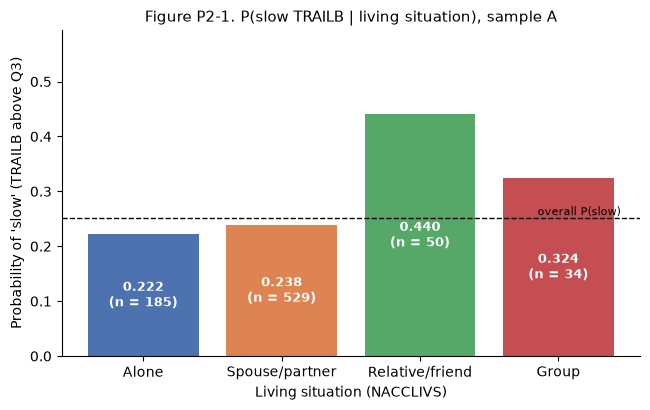

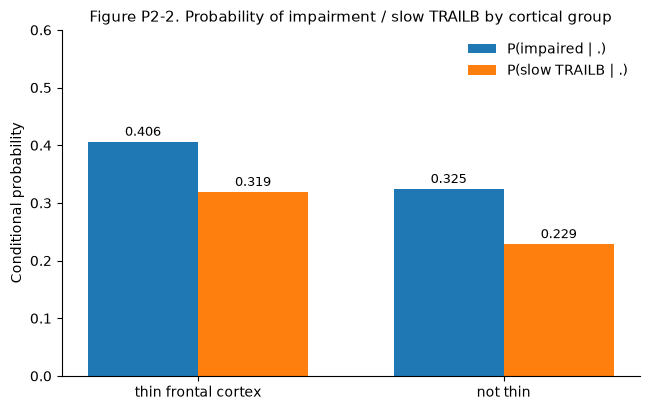

In [6]:
                                                                                 
c1 = cp[cp.event.eq("slow") & cp.given.str.startswith("living")].copy()
fig, ax = plt.subplots(figsize=(6.6, 4.2))
bars = ax.bar(GROUPS, c1["P(event | given)"].values, color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])
for b, (_, r_) in zip(bars, c1.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, r_["P(event | given)"] / 2, f"{r_['P(event | given)']:.3f}\n(n = {int(r_['n_given'])})", ha="center", va="center", fontsize=9, color="white", fontweight="bold")
ax.axhline(c1["P(event)"].iloc[0], color="k", ls="--", lw=1); ax.text(3.45, c1["P(event)"].iloc[0] + 0.006, "overall P(slow)", ha="right", fontsize=8)
ax.set_ylim(0, max(0.5, c1["P(event | given)"].max() * 1.35)); ax.set_ylabel("Probability of 'slow' (TRAILB above Q3)")
ax.set_xlabel("Living situation (NACCLIVS)"); ax.set_title("Figure P2-1. P(slow TRAILB | living situation), sample A")
savefig(fig, "p2_fig1_slow_by_living.png")

                                                                               
sel = cp[cp.given.isin(["thin frontal cortex", "not thin frontal cortex"])]
fig, ax = plt.subplots(figsize=(6.6, 4.2)); xs = np.arange(2); w = 0.36
for i, (ev, lab) in enumerate([("impaired", "P(impaired | .)"), ("slow", "P(slow TRAILB | .)")]):
    v = sel[sel.event == ev].set_index("given").loc[["thin frontal cortex", "not thin frontal cortex"], "P(event | given)"].values
    bars = ax.bar(xs + (i - .5) * w, v, w, label=lab)
    for b, val in zip(bars, v): ax.text(b.get_x() + b.get_width() / 2, val + 0.01, f"{val:.3f}", ha="center", fontsize=9)
ax.set_xticks(xs); ax.set_xticklabels(["thin frontal cortex", "not thin"]); ax.set_ylim(0, 0.6)
ax.set_ylabel("Conditional probability"); ax.legend(frameon=False)
ax.set_title("Figure P2-2. Probability of impairment / slow TRAILB by cortical group")
savefig(fig, "p2_fig2_conditional_by_thin.png")

In [7]:
pairs = [("alone", "slow"), ("thin", "slow"), ("thin", "impaired"), ("alone", "thin"), ("alone", "impaired"), ("slow", "impaired")]
rows = []
for a, b in pairs:
    s = A[[a, b]].dropna(); n = len(s)
    pa, pb = s[a].mean(), s[b].mean(); pab = ((s[a] == 1) & (s[b] == 1)).mean()
    pb_a  = s.loc[s[a] == 1, b].mean(); pb_na = s.loc[s[a] == 0, b].mean()
    rows.append({"A": a, "B": b, "n": n, "P(A)": pa, "P(B)": pb, "P(A and B)": pab, "P(A)P(B)": pa * pb,
                 "ratio": pab / (pa * pb), "P(B|A)": pb_a, "P(B|not A)": pb_na, "P(B|A) - P(B)": pb_a - pb})
ind = pd.DataFrame(rows).round(3)
save_tab(ind, "p2_table_independence")
print(ind.to_string(index=False))
R["independence"] = ind.to_dict(orient="records")

    A        B   n  P(A)  P(B)  P(A and B)  P(A)P(B)  ratio  P(B|A)  P(B|not A)  P(B|A) - P(B)
alone     slow 798 0.232 0.251       0.051     0.058  0.884   0.222       0.259         -0.029
 thin     slow 798 0.239 0.251       0.076     0.060  1.274   0.319       0.229          0.069
 thin impaired 861 0.249 0.345       0.101     0.086  1.179   0.407       0.325          0.062
alone     thin 861 0.226 0.249       0.058     0.056  1.032   0.256       0.246          0.008
alone impaired 861 0.226 0.345       0.048     0.078  0.610   0.210       0.384         -0.135
 slow impaired 798 0.251 0.316       0.152     0.079  1.916   0.605       0.219          0.289


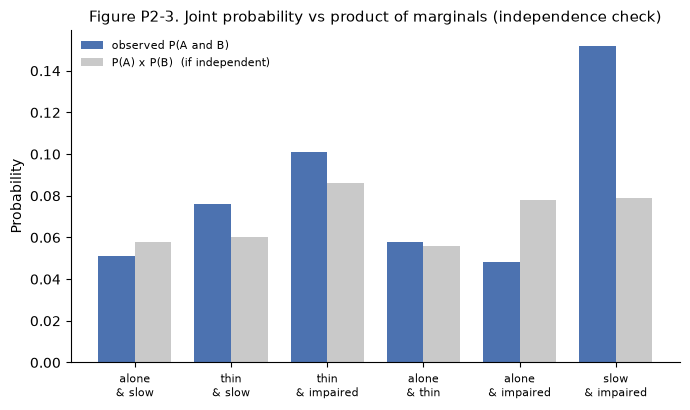

In [8]:
                                                                        
fig, ax = plt.subplots(figsize=(7, 4.2)); xs = np.arange(len(ind)); w = 0.38
ax.bar(xs - w/2, ind["P(A and B)"], w, label="observed P(A and B)", color="#4C72B0")
ax.bar(xs + w/2, ind["P(A)P(B)"], w, label="P(A) x P(B)  (if independent)", color="#C9C9C9")
ax.set_xticks(xs); ax.set_xticklabels([f"{a}\n& {b}" for a, b in zip(ind.A, ind.B)], fontsize=8)
ax.set_ylabel("Probability"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Figure P2-3. Joint probability vs product of marginals (independence check)")
savefig(fig, "p2_fig3_independence.png")

                                   0
n (alone, TRAILB observed)  185.0000
p = overall P(slow)           0.2506
observed count k             41.0000
E[X] = n p                   46.3700
SD[X]                         5.8900
z = (k - np)/SD              -0.9100
P(X <= k)                     0.2060
P(X >= k)                     0.8400


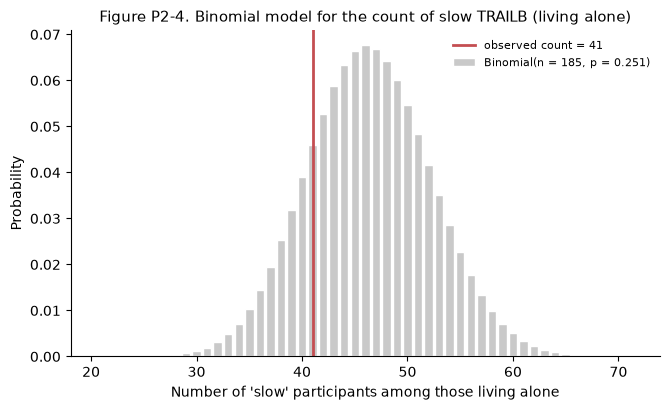

In [9]:
from scipy import stats
S = A[A.slow.notna()].copy()                                                                       
p_hat = float(S.slow.mean())
al = S[S.alone == 1]; n_al = len(al); k_al = int(al.slow.sum())
binom = stats.binom(n_al, p_hat)
b5 = pd.DataFrame([{
    "n (alone, TRAILB observed)": n_al, "p = overall P(slow)": round(p_hat, 4), "observed count k": k_al,
    "E[X] = n p": round(binom.mean(), 2), "SD[X]": round(binom.std(), 2),
    "z = (k - np)/SD": round((k_al - binom.mean()) / binom.std(), 2),
    "P(X <= k)": round(float(binom.cdf(k_al)), 3), "P(X >= k)": round(float(binom.sf(k_al - 1)), 3)}])
save_tab(b5, "p2_table_binomial_alone")
R["binomial"] = b5.iloc[0].to_dict()
print(b5.T)

                                                         
ks = np.arange(max(0, int(binom.mean() - 4.2 * binom.std())), int(binom.mean() + 4.2 * binom.std()) + 1)
fig, ax = plt.subplots(figsize=(6.8, 4.2))
ax.bar(ks, binom.pmf(ks), color="#C9C9C9", edgecolor="white", label=f"Binomial(n = {n_al}, p = {p_hat:.3f})")
ax.axvline(k_al, color="#C44E52", lw=2, label=f"observed count = {k_al}")
ax.set_xlabel("Number of 'slow' participants among those living alone"); ax.set_ylabel("Probability")
ax.set_title("Figure P2-4. Binomial model for the count of slow TRAILB (living alone)"); ax.legend(frameon=False, fontsize=8)
savefig(fig, "p2_fig4_binomial_pmf.png")

                                             0         1         2
subsample size n                        20.000    50.000   185.000
replications                          5000.000  5000.000  5000.000
simulated mean                           5.079    12.568    46.479
binomial n p                             5.013    12.531    46.366
simulated variance                       3.585     9.069    26.957
binomial n p (1-p)                       3.756     9.391    34.745
hypergeometric variance                  3.667     8.813    26.724
finite-population factor (N-n)/(N-1)     0.976     0.939     0.769


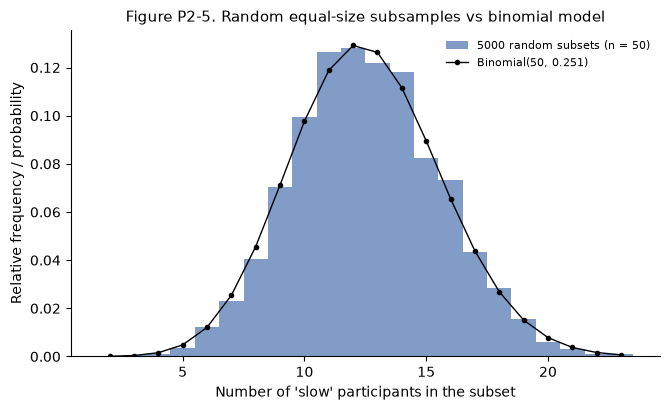

In [10]:
                                                                                                        
                                                                                               
arr = S.slow.values.astype(int); N = len(arr); K = int(arr.sum()); NREP = 5000
rows, sims = [], {}
for n_ in (20, 50, n_al):
    counts = np.array([arr[rng.choice(N, n_, replace=False)].sum() for _ in range(NREP)])
    sims[n_] = counts
    rows.append({"subsample size n": n_, "replications": NREP, "simulated mean": counts.mean(), "binomial n p": n_ * p_hat,
                 "simulated variance": counts.var(ddof=1), "binomial n p (1-p)": n_ * p_hat * (1 - p_hat),
                 "hypergeometric variance": stats.hypergeom(N, K, n_).var(), "finite-population factor (N-n)/(N-1)": (N - n_) / (N - 1)})
sim_tab = pd.DataFrame(rows).round(3); save_tab(sim_tab, "p2_table_binomial_simulation"); print(sim_tab.T)

                                                          
fig, ax = plt.subplots(figsize=(6.8, 4.2)); n_ = 50
vals = np.arange(sims[n_].min(), sims[n_].max() + 1)
ax.hist(sims[n_], bins=np.arange(sims[n_].min() - .5, sims[n_].max() + 1.5), density=True, color="#4C72B0", alpha=.7, label=f"{NREP} random subsets (n = {n_})")
ax.plot(vals, stats.binom.pmf(vals, n_, p_hat), "ko-", ms=3, lw=1, label=f"Binomial({n_}, {p_hat:.3f})")
ax.set_xlabel("Number of 'slow' participants in the subset"); ax.set_ylabel("Relative frequency / probability")
ax.set_title("Figure P2-5. Random equal-size subsamples vs binomial model"); ax.legend(frameon=False, fontsize=8)
savefig(fig, "p2_fig5_binomial_simulation.png")

In [11]:
                                                                                                      
S["age_group"] = np.where(S.NACCAGE < 75, "65-74", "75+")
S["status"] = np.where(S.impaired == 1, "impaired", "normal cognition")
S["sex"] = S.SEX.map({1: "Male", 2: "Female"})
het = pd.concat([S.groupby(c).slow.agg(n="size", p_slow="mean").reset_index().rename(columns={c: "level"}).assign(variable=c)
                 for c in ["status", "age_group", "sex"]])[["variable", "level", "n", "p_slow"]].round(3)
save_tab(het, "p2_table_p_by_characteristics"); print(het.to_string(index=False))

 variable            level   n  p_slow
   status         impaired 252   0.480
   status normal cognition 546   0.145
age_group            65-74 549   0.186
age_group              75+ 249   0.394
      sex           Female 454   0.247
      sex             Male 344   0.256


In [12]:
def normal_check(x, name):
    x = pd.Series(x).dropna().values; n = len(x); m, s = x.mean(), x.std(ddof=1); z = (x - m) / s
    q1, q3 = np.percentile(x, [25, 75]); iqr = q3 - q1
    return {"variable": name, "n": n, "mean": m, "SD": s, "variance": s ** 2, "median": np.median(x), "min": x.min(), "max": x.max(),
            "skewness": stats.skew(x, bias=False), "excess kurtosis": stats.kurtosis(x, bias=False),
            "within 1 SD (normal 68.3%)": (abs(z) < 1).mean() * 100, "within 2 SD (95.4%)": (abs(z) < 2).mean() * 100,
            "within 3 SD (99.7%)": (abs(z) < 3).mean() * 100, "Tukey outliers": int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()),
            "robust SD (IQR/1.349)": iqr / 1.349}
A["log10_TRAILB"] = np.log10(A.TRAILB_obs)
VARS = [("FRONTAL_THK", "Frontal thickness (mm)"), ("TRAILB_obs", "TRAILB (s)"), ("log10_TRAILB", "log10 TRAILB (log10 s)")]
nc = pd.DataFrame([normal_check(A[v], lab) for v, lab in VARS]).round(3)
save_tab(nc, "p2_table_normality"); R["normality"] = nc.to_dict(orient="records"); print(nc.set_index("variable").T)

variable                    Frontal thickness (mm)  TRAILB (s)  log10 TRAILB (log10 s)
n                                          861.000     798.000                 798.000
mean                                         2.379     102.337                   1.949
SD                                           0.124      63.512                   0.216
variance                                     0.015    4033.754                   0.047
median                                       2.387      82.000                   1.914
min                                          1.035      28.000                   1.447
max                                          2.798     300.000                   2.477
skewness                                    -2.519       1.968                   0.774
excess kurtosis                             22.673       3.398                   0.364
within 1 SD (normal 68.3%)                  76.887      87.469                  72.180
within 2 SD (95.4%)                        

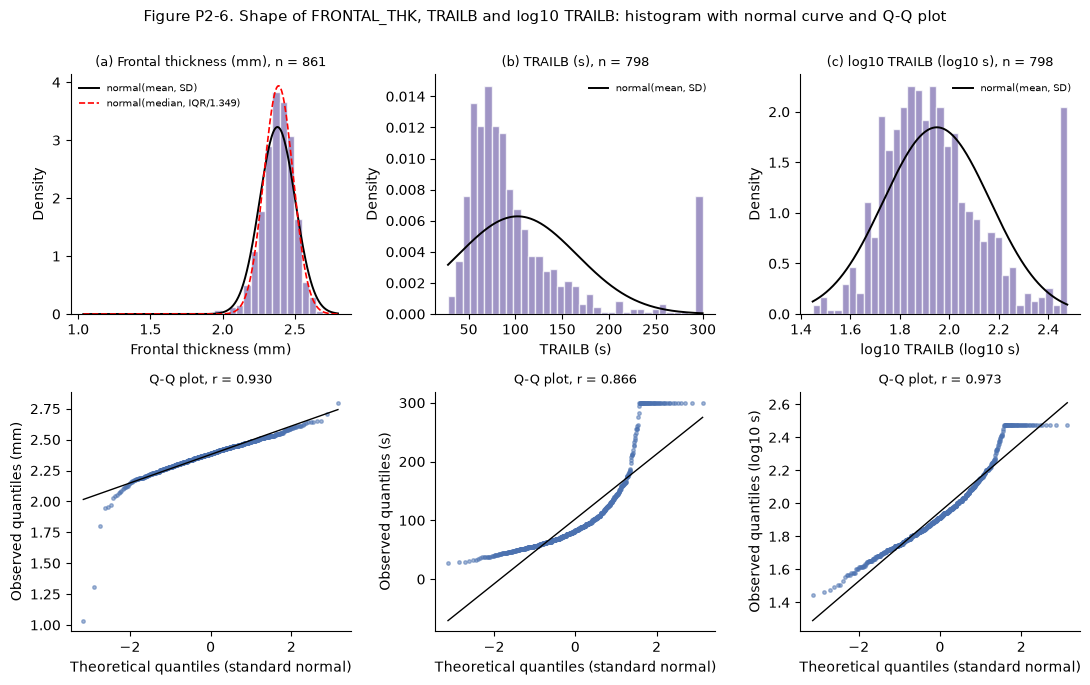

             probability  empirical  normal approx. (raw scale)  normal approx. (robust for thickness / log10 scale for TRAILB)
P(FRONTAL_THK < 2.20 mm)     0.0499                      0.0734                                                          0.0326
P(FRONTAL_THK < 1.90 mm)     0.0035                      0.0001                                                          0.0000
       P(TRAILB > 150 s)     0.1391                      0.2265                                                          0.1471
       P(TRAILB > 200 s)     0.0852                      0.0621                                                          0.0518


In [13]:
                                                                    
fig, axs = plt.subplots(2, 3, figsize=(11, 6.8))
for j, (v, lab) in enumerate(VARS):
    x = A[v].dropna().values; m, s = x.mean(), x.std(ddof=1); xs = np.linspace(x.min(), x.max(), 300)
    ax = axs[0, j]; ax.hist(x, bins=35, density=True, color="#8172B2", alpha=.75, edgecolor="white")
    ax.plot(xs, stats.norm.pdf(xs, m, s), "k-", lw=1.4, label="normal(mean, SD)")
    if v == "FRONTAL_THK":
        q1, q3 = np.percentile(x, [25, 75]); ax.plot(xs, stats.norm.pdf(xs, np.median(x), (q3 - q1) / 1.349), "r--", lw=1.2, label="normal(median, IQR/1.349)")
    ax.set_xlabel(lab); ax.set_ylabel("Density"); ax.set_title(f"({'abc'[j]}) {lab}, n = {len(x)}", fontsize=9.5); ax.legend(frameon=False, fontsize=7)
    ax = axs[1, j]; (osm, osr), (slope, icpt, r_) = stats.probplot(x, dist="norm")
    ax.plot(osm, osr, "o", ms=2.5, alpha=.5, color="#4C72B0"); ax.plot(osm, slope * osm + icpt, "k-", lw=1)
    ax.set_xlabel("Theoretical quantiles (standard normal)"); ax.set_ylabel(f"Observed quantiles ({lab.split('(')[-1].rstrip(')')})"); ax.set_title(f"Q-Q plot, r = {r_:.3f}", fontsize=9.5)
fig.suptitle("Figure P2-6. Shape of FRONTAL_THK, TRAILB and log10 TRAILB: histogram with normal curve and Q-Q plot", fontsize=10.5, y=1.0)
savefig(fig, "p2_fig6_normality.png")

                                                                
x_t = A.FRONTAL_THK.dropna().values; x_l = A.log10_TRAILB.dropna().values; x_r = A.TRAILB_obs.dropna().values
q1t, q3t = np.percentile(x_t, [25, 75]); rob = (q3t - q1t) / 1.349
chk = pd.DataFrame([
 ("P(FRONTAL_THK < 2.20 mm)", (x_t < 2.20).mean(), stats.norm.cdf(2.20, x_t.mean(), x_t.std(ddof=1)), stats.norm.cdf(2.20, np.median(x_t), rob)),
 ("P(FRONTAL_THK < 1.90 mm)", (x_t < 1.90).mean(), stats.norm.cdf(1.90, x_t.mean(), x_t.std(ddof=1)), stats.norm.cdf(1.90, np.median(x_t), rob)),
 ("P(TRAILB > 150 s)", (x_r > 150).mean(), stats.norm.sf(150, x_r.mean(), x_r.std(ddof=1)), stats.norm.sf(np.log10(150), x_l.mean(), x_l.std(ddof=1))),
 ("P(TRAILB > 200 s)", (x_r > 200).mean(), stats.norm.sf(200, x_r.mean(), x_r.std(ddof=1)), stats.norm.sf(np.log10(200), x_l.mean(), x_l.std(ddof=1))),
], columns=["probability", "empirical", "normal approx. (raw scale)", "normal approx. (robust for thickness / log10 scale for TRAILB)"]).round(4)
save_tab(chk, "p2_table_normal_approx_probabilities"); print(chk.to_string(index=False))

In [14]:
x = A.TRAILB_obs.dropna(); pmf = x.value_counts(normalize=True).sort_index()                                                 
EX = float((pmf.index.values * pmf.values).sum()); EX2 = float(((pmf.index.values ** 2) * pmf.values).sum()); VarX = EX2 - EX ** 2
print(f"TRAILB: E[X] = sum x p(x) = {EX:.2f} s | Var = E[X^2] - E[X]^2 = {VarX:.1f} s^2 | mean = {x.mean():.2f} | var (ddof=0) = {x.var(ddof=0):.1f}")
assert np.isclose(EX, x.mean()) and np.isclose(VarX, x.var(ddof=0))

ev = pd.DataFrame([
 {"variable": "X = TRAILB", "unit": "s", "E": x.mean(), "Var": x.var(ddof=1), "SD": x.std(ddof=1), "unit of Var": "s^2"},
 {"variable": "Y = FRONTAL_THK", "unit": "mm", "E": A.FRONTAL_THK.mean(), "Var": A.FRONTAL_THK.var(ddof=1), "SD": A.FRONTAL_THK.std(ddof=1), "unit of Var": "mm^2"},
 {"variable": "log10 TRAILB", "unit": "log10 s", "E": A.log10_TRAILB.mean(), "Var": A.log10_TRAILB.var(ddof=1), "SD": A.log10_TRAILB.std(ddof=1), "unit of Var": "log10(s)^2"},
]).round(4)
save_tab(ev, "p2_table_expectation_variance"); print(ev.to_string(index=False))

                                                  
ind_ev = pd.DataFrame([{"event": e, "p = E[indicator]": A[e].mean(), "Var = p(1-p)": A[e].mean() * (1 - A[e].mean())} for e in ["alone", "slow", "thin", "impaired"]]).round(4)
save_tab(ind_ev, "p2_table_indicator_expectation_variance"); print(ind_ev.to_string(index=False))

                                                            
cev = A.groupby("LIV_grp").agg(n=("NACCID", "size"), n_TRAILB=("TRAILB_obs", "count"), E_TRAILB=("TRAILB_obs", "mean"), Var_TRAILB=("TRAILB_obs", "var"),
                               E_THK=("FRONTAL_THK", "mean"), Var_THK=("FRONTAL_THK", "var")).reindex(GROUPS).round(4)
save_tab(cev.reset_index(), "p2_table_conditional_expectation"); print(cev)
R["EV"] = ev.to_dict(orient="records")

TRAILB: E[X] = sum x p(x) = 102.34 s | Var = E[X^2] - E[X]^2 = 4028.7 s^2 | mean = 102.34 | var (ddof=0) = 4028.7
       variable    unit        E       Var      SD unit of Var
     X = TRAILB       s 102.3371 4033.7545 63.5118         s^2
Y = FRONTAL_THK      mm   2.3794    0.0153  0.1236        mm^2
   log10 TRAILB log10 s   1.9495    0.0467  0.2160  log10(s)^2
   event  p = E[indicator]  Var = p(1-p)
   alone            0.2265        0.1752
    slow            0.2506        0.1878
    thin            0.2485        0.1868
impaired            0.3449        0.2260
                   n  n_TRAILB  E_TRAILB  Var_TRAILB   E_THK  Var_THK
LIV_grp                                                              
Alone            195       185  100.4757   3548.2290  2.3842   0.0112
Spouse/partner   574       529  101.1890   4252.8316  2.3760   0.0175
Relative/friend   56        50  117.4600   4748.1310  2.3966   0.0081
Group             36        34  108.0882   2120.5071  2.3811   0.0135


                                                  pair   n   value         unit
                                Cov(thickness, TRAILB) 798 -1.1137       mm x s
                          Cov(thickness, log10 TRAILB) 798 -0.0036 mm x log10 s
                               Pearson r (descriptive) 798 -0.1432            -
                            Spearman rho (descriptive) 798 -0.0987            -
Cov excluding 2 thickness values < 1.5 mm (check only) 796 -1.0031       mm x s
                 n  mean_thickness  mean_TRAILB  median_TRAILB
thk_quartile                                                  
Q1 (thinnest)  201           2.237      113.433           87.0
Q2             198           2.355      106.551           84.0
Q3             200           2.422       98.015           82.5
Q4 (thickest)  199           2.512       91.281           77.0


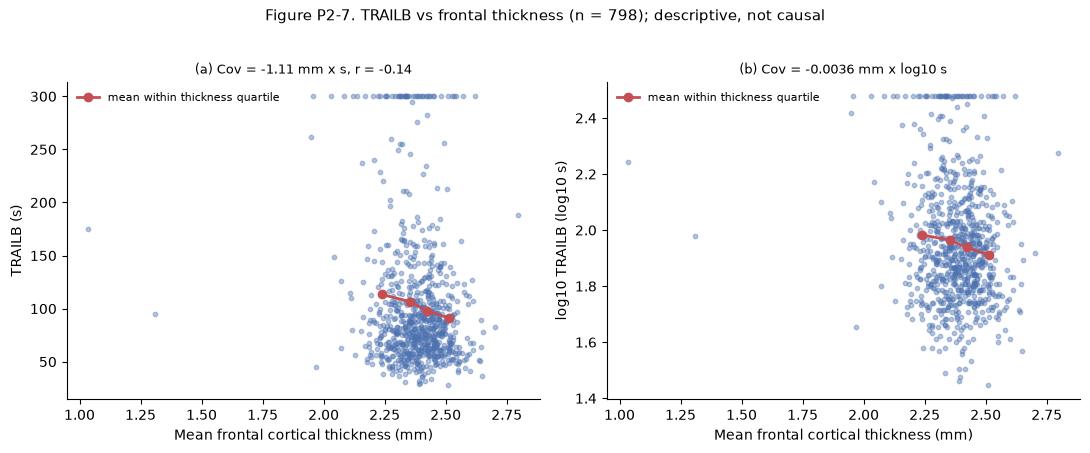

In [15]:
J = A[["TRAILB_obs", "FRONTAL_THK"]].dropna().copy(); J["log10_TRAILB"] = np.log10(J.TRAILB_obs)
cov_raw = float(np.cov(J.FRONTAL_THK, J.TRAILB_obs)[0, 1]); cov_log = float(np.cov(J.FRONTAL_THK, J.log10_TRAILB)[0, 1])
r_p = float(J[["FRONTAL_THK", "TRAILB_obs"]].corr().iloc[0, 1]); r_s = float(J[["FRONTAL_THK", "TRAILB_obs"]].corr(method="spearman").iloc[0, 1])
Jt = J[J.FRONTAL_THK >= 1.5]                                                                                 
cov_chk = float(np.cov(Jt.FRONTAL_THK, Jt.TRAILB_obs)[0, 1])
cv = pd.DataFrame([
 {"pair": "Cov(thickness, TRAILB)", "n": len(J), "value": cov_raw, "unit": "mm x s"},
 {"pair": "Cov(thickness, log10 TRAILB)", "n": len(J), "value": cov_log, "unit": "mm x log10 s"},
 {"pair": "Pearson r (descriptive)", "n": len(J), "value": r_p, "unit": "-"},
 {"pair": "Spearman rho (descriptive)", "n": len(J), "value": r_s, "unit": "-"},
 {"pair": f"Cov excluding {len(J) - len(Jt)} thickness values < 1.5 mm (check only)", "n": len(Jt), "value": cov_chk, "unit": "mm x s"},
]).round(4)
save_tab(cv, "p2_table_covariance"); R["covariance"] = cv.to_dict(orient="records"); print(cv.to_string(index=False))

                                                                                  
J["thk_quartile"] = pd.qcut(J.FRONTAL_THK, 4, labels=["Q1 (thinnest)", "Q2", "Q3", "Q4 (thickest)"])
qm = J.groupby("thk_quartile").agg(n=("TRAILB_obs", "size"), mean_thickness=("FRONTAL_THK", "mean"), mean_TRAILB=("TRAILB_obs", "mean"), median_TRAILB=("TRAILB_obs", "median")).round(3)
save_tab(qm.reset_index(), "p2_table_trailb_by_thickness_quartile"); print(qm)

                                                           
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, ycol, ylab in [(axs[0], "TRAILB_obs", "TRAILB (s)"), (axs[1], "log10_TRAILB", "log10 TRAILB (log10 s)")]:
    ax.scatter(J.FRONTAL_THK, J[ycol], s=10, alpha=.4, color="#4C72B0")
    mm_ = J.groupby("thk_quartile")[[ "FRONTAL_THK", ycol]].mean(); ax.plot(mm_.FRONTAL_THK, mm_[ycol], "o-", color="#C44E52", lw=2, label="mean within thickness quartile")
    ax.set_xlabel("Mean frontal cortical thickness (mm)"); ax.set_ylabel(ylab); ax.legend(frameon=False, fontsize=8)
axs[0].set_title(f"(a) Cov = {cov_raw:.2f} mm x s, r = {r_p:.2f}", fontsize=9.5); axs[1].set_title(f"(b) Cov = {cov_log:.4f} mm x log10 s", fontsize=9.5)
fig.suptitle(f"Figure P2-7. TRAILB vs frontal thickness (n = {len(J)}); descriptive, not causal", fontsize=10.5, y=1.02)
savefig(fig, "p2_fig7_scatter_covariance.png")

test                              slow TRAILB (UDS)  thin frontal cortex (MRI)
n                                          798.0000                   861.0000
prior P(D)                                   0.3158                     0.3449
sensitivity P(T|D)                           0.4802                     0.2929
specificity P(not T|not D)                   0.8553                     0.7748
P(T)                                         0.2506                     0.2485
posterior P(D|T)                             0.6050                     0.4065
P(D|not T)                                   0.2191                     0.3246
positive likelihood ratio                    3.3186                     1.3009
prior odds                                   0.4615                     0.5266
posterior odds = prior odds x LR             1.5316                     0.6850


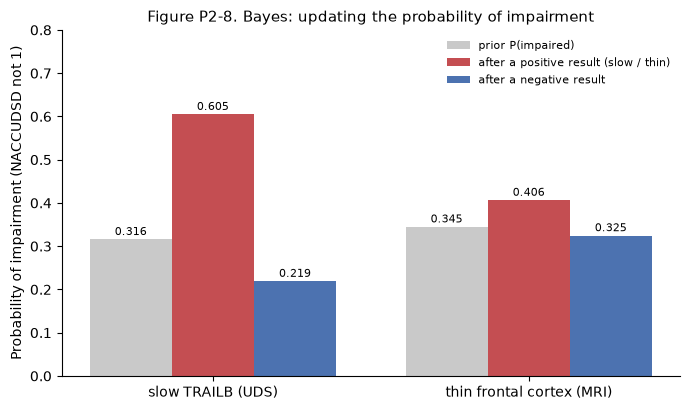

In [16]:
def bayes(data, D, T, label):
    s = data[[D, T]].dropna(); n = len(s)
    pD = s[D].mean(); sens = s.loc[s[D] == 1, T].mean(); spec = 1 - s.loc[s[D] == 0, T].mean()
    pT = sens * pD + (1 - spec) * (1 - pD)                                                 
    post_pos = sens * pD / pT; post_neg = (1 - sens) * pD / (1 - pT)            
    d_pos = s.loc[s[T] == 1, D].mean(); d_neg = s.loc[s[T] == 0, D].mean()                  
    assert np.isclose(post_pos, d_pos) and np.isclose(post_neg, d_neg)
    lr = sens / (1 - spec)
    return {"test": label, "n": n, "prior P(D)": pD, "sensitivity P(T|D)": sens, "specificity P(not T|not D)": spec, "P(T)": pT,
            "posterior P(D|T)": post_pos, "P(D|not T)": post_neg, "positive likelihood ratio": lr,
            "prior odds": pD / (1 - pD), "posterior odds = prior odds x LR": pD / (1 - pD) * lr}
bt = pd.DataFrame([bayes(A, "impaired", "slow", "slow TRAILB (UDS)"), bayes(A, "impaired", "thin", "thin frontal cortex (MRI)")]).round(4)
save_tab(bt, "p2_table_bayes"); R["bayes"] = bt.to_dict(orient="records"); print(bt.set_index("test").T)

                                                        
fig, ax = plt.subplots(figsize=(7, 4.2)); xs = np.arange(len(bt)); w = 0.26
for i, (col, lab, colr) in enumerate([("prior P(D)", "prior P(impaired)", "#C9C9C9"), ("posterior P(D|T)", "after a positive result (slow / thin)", "#C44E52"), ("P(D|not T)", "after a negative result", "#4C72B0")]):
    b = ax.bar(xs + (i - 1) * w, bt[col], w, label=lab, color=colr)
    for rect, v in zip(b, bt[col]): ax.text(rect.get_x() + rect.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=8)
ax.set_xticks(xs); ax.set_xticklabels(bt.test); ax.set_ylim(0, 0.8); ax.set_ylabel("Probability of impairment (NACCUDSD not 1)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Figure P2-8. Bayes: updating the probability of impairment")
savefig(fig, "p2_fig8_bayes.png")

In [17]:
with open(TAB / "p2_key_numbers.json", "w") as f:
    json.dump(R, f, indent=1, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else str(o))
print("tables:", len(list(TAB.glob("p2_*.csv"))), "| figures:", len(list(FIG.glob("p2_fig*.png"))))

tables: 17 | figures: 8
